# Measure G

From `FINDINGS.md`:

> Allowing private vehicles on the Great Highway in Sunset Dunes Park. Yes 112,765, No 215,803. The yes share is 34.3 percent.
>
> Precinct shares run from 18.9 percent to 33.8 percent to 51.5 percent, the widest range of these six contests. The ocean side voted yes at a much higher rate than the center of the city. This is the sharp east-west split among the local measures (correlation of the precinct yes share with easting, −0.51), and the yes share is also higher toward the south (correlation with latitude, −0.37). District 1 is 49.6 percent yes and District 4 is 49.4 percent. District 11 is 45.0 percent and District 7 is 39.9 percent. District 8 is 21.3 percent, District 5 is 22.6 percent, and District 6 is 25.2 percent. The spread from District 8 to District 1 is 28.3 points.
>
> The yes share rises with the non-Hispanic Asian share of the precinct (r = 0.67) and with the foreign-born share (r = 0.46). It is lower where the renter share is higher (r = −0.52) and where the non-Hispanic white share is higher (r = −0.52).

Every number below is computed from the files in `source/`. Run the setup cell first, then the rest in order (Runtime → Run all). The last cell lists each number the memo section quotes next to the value computed here, and stops with an error if any differ.

In [1]:
# Run this cell first. It finds the sf-2026-drive folder (on Google Drive in Colab, or on
# this computer) and loads the shared code in notebooks/sf2026.py.
import subprocess
import sys
from pathlib import Path

try:
    import geopandas  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "geopandas"], check=True)

FOLDER_NAME = "sf-2026-drive"


def is_root(path: Path) -> bool:
    return (path / "source" / "precinct_results.csv").exists() and (path / "notebooks" / "sf2026.py").exists()


def find_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if is_root(candidate):
            return candidate
    try:
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError("Open this notebook from inside the sf-2026-drive folder.")
    drive.mount("/content/drive")
    bases = [Path("/content/drive/MyDrive"), Path("/content/drive/Shareddrives")]
    for base in bases:
        if is_root(base / FOLDER_NAME):
            return base / FOLDER_NAME
    for base in bases:
        if base.exists():
            for helper in base.rglob("sf2026.py"):
                if is_root(helper.parent.parent):
                    return helper.parent.parent
    raise FileNotFoundError(
        f"Could not find the {FOLDER_NAME} folder on Drive. If you renamed it, set FOLDER_NAME above."
    )


ROOT = find_root()
sys.path.insert(0, str(ROOT / "notebooks"))
import pandas as pd
import sf2026 as sf

pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
data = sf.load(ROOT)
check = sf.MemoCheck()
print(f"Using the {ROOT.name} folder: {len(data)} precincts")

Using the sf-2026-drive folder: 514 precincts


## Citywide result

In [2]:
city = sf.citywide(data, "measure_g__yes", "measure_g__no")
city

{'measure_g__yes': 112765,
 'measure_g__no': 215803,
 'share_pct': 34.32014073190329,
 'margin': -103038}

## Precinct and supervisor-district geography

In [3]:
share, votes = sf.two_way(data, "measure_g__yes", "measure_g__no")
enough = data["ballots"] >= sf.MIN_BALLOTS
districts = sf.by_district(data, "measure_g__yes", "measure_g__no")
print("Precinct range, 10th / 50th / 90th percentile:", [round(v, 1) for v in sf.percentile_range(share, enough)])
districts.round(1).to_frame("Yes share, percent")

Precinct range, 10th / 50th / 90th percentile: [np.float64(18.9), np.float64(33.8), np.float64(51.5)]


,"Yes share, percent"
Supervisorial,
1,49.60
2,32.00
3,30.00
4,49.40
5,22.60
6,25.20
7,39.90
8,21.30
9,26.50


In [4]:
check.number("Yes votes", 112765, city["measure_g__yes"], 0)
check.number("No votes", 215803, city["measure_g__no"], 0)
check.number("Yes share, percent", 34.3, city["share_pct"])
for name, memo, value in zip(["10th", "50th", "90th"], [18.9, 33.8, 51.5], sf.percentile_range(share, enough)):
    check.number(f"Precinct share, {name} percentile", memo, value)
check.number("Yes share, District 1", 49.6, districts[1])
check.number("Yes share, District 4", 49.4, districts[4])
check.number("Yes share, District 11", 45.0, districts[11])
check.number("Yes share, District 7", 39.9, districts[7])
check.number("Yes share, District 8", 21.3, districts[8])
check.number("Yes share, District 5", 22.6, districts[5])
check.number("Yes share, District 6", 25.2, districts[6])
check.fact("Highest and lowest district", "District 1 and District 8",
           f"District {districts.idxmax()} and District {districts.idxmin()}",
           (districts.idxmax(), districts.idxmin()) == (1, 8))
check.number("Spread from District 8 to District 1, points", 28.3, districts.max() - districts.min())

## The widest range, and the east-west split

In [5]:
featured = {"Governor (Hilton)": ("hilton", "becerra", None), "CA-11 (Chan)": ("chan", "wiener", 11)}
featured.update({m: (f"measure_{m[-1].lower()}__yes", f"measure_{m[-1].lower()}__no", None)
                 for m in ["Measure B", "Measure G", "Measure I", "Measure D"]})
ranges = {}
for name, (named, other, district) in featured.items():
    contest_share, _ = sf.two_way(data, named, other)
    keep = data["ballots"] >= sf.MIN_BALLOTS
    if district:
        keep = keep & (data["Congressional"] == district)
    low, _mid, high = sf.percentile_range(contest_share, keep)
    ranges[name] = high - low
ranges = pd.Series(ranges, name="10th to 90th percentile, points").sort_values(ascending=False)
check.fact("Widest precinct range of the six contests", "Measure G", ranges.idxmax(), ranges.idxmax() == "Measure G")

geography = sf.geography_correlations(data, share, votes >= sf.MIN_BALLOTS)
check.number("Correlation with easting", -0.51, geography["east-west (easting)"], 2)
check.number("Correlation with latitude", -0.37, geography["north-south (latitude)"], 2)
screen = sf.screen_measures(data, sf.local_measures(data)).set_index("contest")
sharp = screen.index[screen["east_west_r"].abs() >= 0.5].tolist()
check.fact("The one local measure with an east-west correlation of 0.5 or more", "Measure G", sharp, sharp == ["Measure G"])
display(ranges.to_frame())
geography.to_frame()

,"10th to 90th percentile, points"
Measure G,32.52
Measure B,26.20
Measure I,26.11
CA-11 (Chan),23.93
Measure D,23.64
Governor (Hilton),18.41


,r
east-west (easting),-0.51
north-south (latitude),-0.37


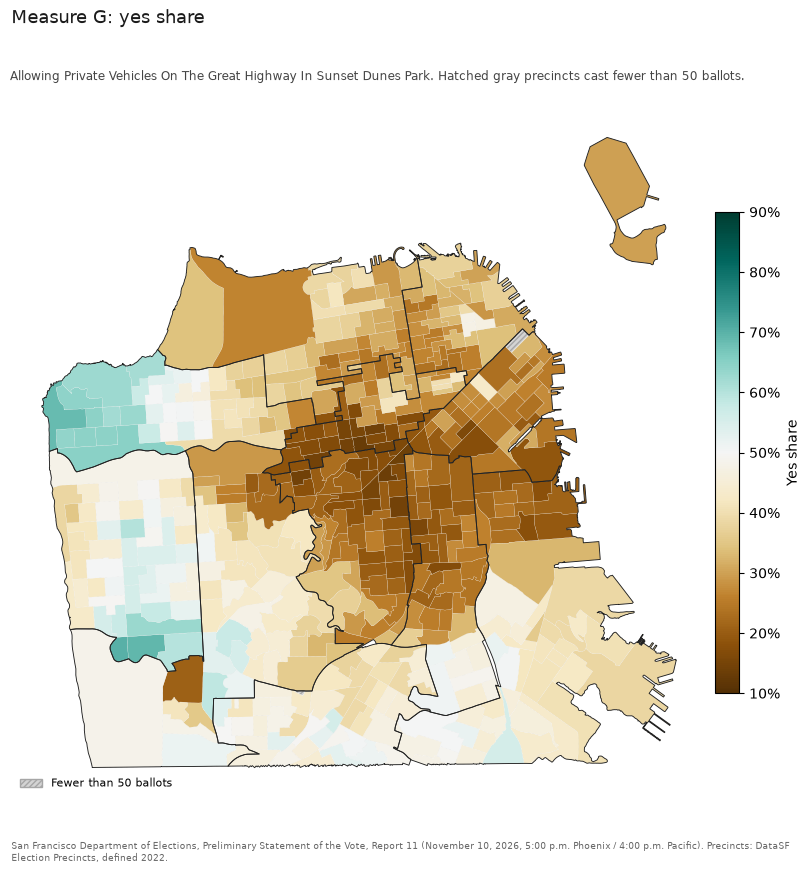

In [6]:
sf.rate_map(data, share, votes, "Measure G: yes share",
            "Allowing Private Vehicles On The Great Highway In Sunset Dunes Park. Hatched gray precincts cast fewer than 50 ballots.",
            "Yes share")

## Census comparison

,r
Non-Hispanic Asian,0.67
Non-Hispanic white,-0.52
Hispanic,-0.09
Bachelor's degree or higher,-0.43
Renters,-0.52
"Households at $150,000+",-0.16
Foreign born,0.46


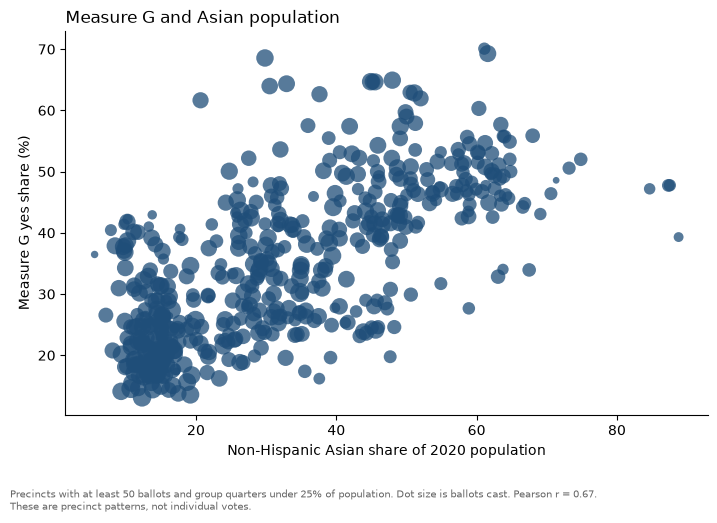

In [7]:
r = sf.census_correlations(data, share, sf.census_frame(data))
display(r.to_frame())
check.number("Correlation with Non-Hispanic Asian", 0.67, r["Non-Hispanic Asian"], 2)
check.number("Correlation with Foreign born", 0.46, r["Foreign born"], 2)
check.number("Correlation with Renters", -0.52, r["Renters"], 2)
check.number("Correlation with Non-Hispanic white", -0.52, r["Non-Hispanic white"], 2)
keep = sf.census_frame(data)
sf.census_scatter(data[keep].assign(share=share[keep]), "share", "nh_asian_share", None,
                  "Measure G and Asian population", "Non-Hispanic Asian share of 2020 population", "Measure G yes share (%)");

## Numbers the memo quotes

In [8]:
check.report();

,claim,memo,computed,matches
0,Yes votes,"112,765","112,765",yes
1,No votes,"215,803","215,803",yes
2,"Yes share, percent",34.3,34.3,yes
3,"Precinct share, 10th percentile",18.9,18.9,yes
4,"Precinct share, 50th percentile",33.8,33.8,yes
5,"Precinct share, 90th percentile",51.5,51.5,yes
6,"Yes share, District 1",49.6,49.6,yes
7,"Yes share, District 4",49.4,49.4,yes
8,"Yes share, District 11",45.0,45.0,yes
9,"Yes share, District 7",39.9,39.9,yes


All 23 numbers checked match the memo.
